In [1]:
# packages

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
from pandas_datareader import data as pdr

In [3]:
import matplotlib.pyplot as plt
from IPython.display import display

In [7]:
PROJECT_ROOT=Path("/Users/yaasarpong/Desktop/PHD/Year 4 fall/finance-volatility").resolve()

In [8]:
DATA_DIR = PROJECT_ROOT / "data"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = PROJECT_ROOT / "figures"

In [9]:
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

In [11]:
data = pd.read_csv(DATA_DIR / "sp500_trading_data.csv", parse_dates=["date"])

In [12]:
data = (data.loc[data["date"] <= pd.Timestamp("2024-12-31")].
    sort_values("date").
    reset_index(drop=True))

In [13]:
data["sp500"] = pd.to_numeric(data["sp500"],errors="raise")

In [14]:
assert data["date"].notna().all(),"Missing dates found."
assert not data["date"].duplicated().any(),"Duplicate dates found."
assert np.isfinite(data["sp500"]).all(),"Invalid prices found."
assert data["sp500"].gt(0).all(),"Prices must be positive."

In [15]:
print("Observations:",len(data))

Observations: 2075


In [16]:
print("Date range:", data["date"].min(),"to",data["date"].max())

Date range: 2016-10-03 00:00:00 to 2024-12-31 00:00:00


In [17]:
#calculate returns and align the target

In [18]:
data["log_return"]=100*np.log(data["sp500"]).diff()

In [20]:
data["absolute_return"] = data["log_return"].abs()

In [21]:
data["target_next_day"] = data["absolute_return"].shift(-1)

In [22]:
data["target_date"] = data["date"].shift(-1)

In [23]:
display(data[["date","absolute_return","target_date","target_next_day"]].
    head(8))

,date,absolute_return,target_date,target_next_day
0,2016-10-03,NaN,2016-10-04,0.496790
1,2016-10-04,0.496790,2016-10-05,0.428749
2,2016-10-05,0.428749,2016-10-06,0.048143
3,2016-10-06,0.048143,2016-10-07,0.325877
4,2016-10-07,0.325877,2016-10-10,0.459537
5,2016-10-10,0.459537,2016-10-11,1.252461
6,2016-10-11,1.252461,2016-10-12,0.114596
7,2016-10-12,0.114596,2016-10-13,0.310413


In [24]:
# create the baseline forecasts

In [25]:
absolute_returns = data["absolute_return"]

In [26]:
# A. Historical mean: all available absolute returns through today.
data["historical_mean"] = (absolute_returns.expanding(min_periods=20).mean())

In [27]:
# B. Previous-period: tomorrow's movement equals today's movement.
data["previous_period"]=absolute_returns

In [28]:
# C. Rolling means: average of the most recent observations.
for window in [5,10,20]:data[f"rolling_{window}"]=(
    absolute_returns.rolling(window=window,min_periods=window).mean())

In [29]:
# D. Exponentially weighted mean: more weight on recent observations.
data["ewm_20"]=(absolute_returns.
    ewm(span=20,adjust=False,min_periods=20).mean())

In [30]:
forecast_columns = ["historical_mean","previous_period","rolling_5",
    "rolling_10","rolling_20","ewm_20",]

In [31]:
# select the validation observations

In [32]:
validation_mask = data["target_date"].between(
    pd.Timestamp("2023-01-01"), pd.Timestamp("2024-12-31"))

In [33]:
validation=(data.loc[validation_mask,["date","target_date",
                                      "target_next_day",*forecast_columns,]]
            .dropna(subset=["target_next_day",*forecast_columns])
            .copy())

In [35]:
assert not validation.empty, "No validation observations found."
assert (
    validation["date"] < validation["target_date"]
).all(), "Forecast dates must precede outcome dates."

assert np.isfinite(
    validation[["target_next_day", *forecast_columns]].to_numpy()
).all(), "Nonfinite values found."

In [36]:
# calculate MAE,RMSE, and bias

In [37]:
actual = validation["target_next_day"]

scores=[]

for method in forecast_columns:
    error = validation[method]-actual
    scores.append({"method":method, "n_forecasts":len(error),"MAE":error.abs().mean(),
                   "RMSE":np.sqrt((error ** 2).mean()),"Bias":error.mean(),})
    

In [38]:
performance=(pd.DataFrame(scores).set_index("method").sort_values("MAE"))

In [39]:
display(performance.round(4))

,n_forecasts,MAE,RMSE,Bias
method,,,,
ewm_20,502,0.4210,0.5280,0.0061
rolling_10,502,0.4233,0.5326,0.0012
rolling_20,502,0.4242,0.5317,0.0050
rolling_5,502,0.4377,0.5572,0.0009
historical_mean,502,0.4577,0.5456,0.1448
previous_period,502,0.5631,0.7370,-0.0003


In [40]:
print("Lowest MAE:",performance["MAE"].idxmin())
print("Lowest RMSE:",performance["RMSE"].idxmin())
print("Bias closest to zero:", performance["Bias"].abs().idxmin())

Lowest MAE: ewm_20
Lowest RMSE: ewm_20
Bias closest to zero: previous_period


In [41]:
# plot the performance comparison

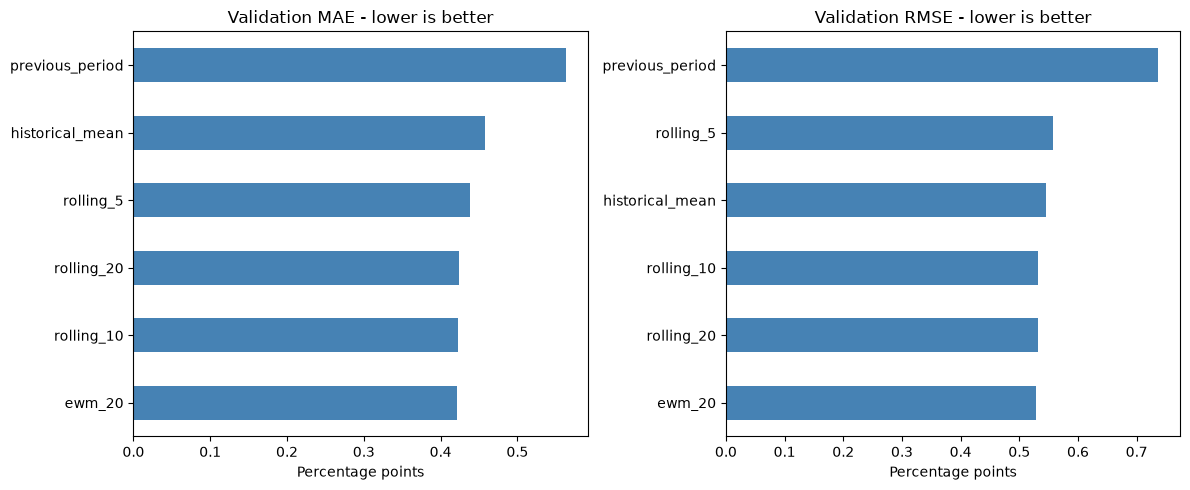

In [42]:
fig,axes = plt.subplots(1,2,figsize=(12,5))

for ax, metric in zip(axes,["MAE","RMSE"]):
    performance[metric].sort_values().plot(kind="barh",ax=ax,color="steelblue")

    ax.set_title(f"Validation {metric} - lower is better")
    ax.set_xlabel("Percentage points")
    ax.set_ylabel("")

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "day11_baseline_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

In [43]:
# save your results 

In [44]:
validation.to_csv(RESULTS_DIR / "day11_validation_predictions.csv",
    index=False)

performance.to_csv(RESULTS_DIR / "day11_baseline_performance.csv")

print("Day 11 predictions, performance table, and figures saved.")

Day 11 predictions, performance table, and figures saved.


**Your results show that `ewm_20` is the best-performing baseline on both MAE and RMSE.** The 10-day and 20-day rolling means are close behind.

| Method | MAE | RMSE | Bias |
|---|---:|---:|---:|
| **Exponentially weighted mean** | **0.4210** | **0.5280** | 0.0061 |
| 10-day rolling mean | 0.4233 | 0.5326 | 0.0012 |
| 20-day rolling mean | 0.4242 | 0.5317 | 0.0050 |
| 5-day rolling mean | 0.4377 | 0.5572 | 0.0009 |
| Historical mean | 0.4577 | 0.5456 | 0.1448 |
| Previous-period | 0.5631 | 0.7370 | −0.0003 |

All methods have **502 forecasts**, consistent with a common evaluation sample. Errors are measured in **percentage points**.

**What these results mean**

- **Giving more weight to recent observations worked best here.** Compared with the historical mean, `ewm_20` reduced MAE by approximately **8.0%** and RMSE by **3.2%**.
- **Its advantage over the other leading methods is small.** Its MAE is only about **0.5% lower** than the 10-day rolling mean. These results alone do not establish a statistically meaningful difference.
- **The historical mean overpredicted on average.** Its bias of `0.1448` means its forecasts exceeded actual absolute returns by about **0.145 percentage points on average**. This is consistent with earlier, more volatile observations keeping the historical average elevated.
- **Yesterday’s movement alone was a weak forecast.** The previous-period method had the largest MAE and RMSE, despite having bias closest to zero. Its positive and negative errors largely cancelled; that did not make its individual forecasts accurate.
- **Averaging several recent observations helped.** The 10-day, 20-day, and exponentially weighted averages all improved on the historical mean under both metrics. The 5-day average improved MAE but had a slightly worse RMSE.

**Your target alignment also looks correct in the displayed rows.** For example, October 3’s target is `0.496790`, which matches October 4’s absolute return. The first `NaN` is expected because there is no preceding price to calculate the first return. Leave it missing; the validation filtering handles it.

Your displayed data now begin on **October 3, 2016**. Record that actual start date in your project documentation so it matches this download.

**For the next modeling stage, retain `ewm_20` as your leading baseline**, alongside the historical mean for reference. Keep 2025 untouched and compare later models on the same forecast dates. Once you save these outputs and add your interpretation to the notebook, your Day 11 work is complete.
